In [161]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import re
import string
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from wordcloud import WordCloud
import joblib
import inspect

In [16]:
df = pd.read_csv("../data/all_tickets_processed_improved_v3.csv")
df.head()

,Document,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,Miscellaneous


In [19]:
df.tail()

,Document,Topic_group
47832,git space for a project issues with adding use...,Access
47833,error sent july error hi guys can you help out...,Miscellaneous
47834,connection issues sent tuesday july connection...,Hardware
47835,error cube reports sent tuesday july error hel...,HR Support
47836,running out on extensions hello please be advi...,Hardware


In [18]:
df.shape

(47837, 2)

In [20]:
df.columns

Index(['Document', 'Topic_group'], dtype='str')

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Document     47837 non-null  str  
 1   Topic_group  47837 non-null  str  
dtypes: str(2)
memory usage: 747.6 KB


In [22]:
df.dtypes

Document       str
Topic_group    str
dtype: object

In [23]:
df.isnull().sum()

Document       0
Topic_group    0
dtype: int64

In [24]:
df.duplicated().sum()

np.int64(0)

In [25]:
df.nunique()

Document       47837
Topic_group        8
dtype: int64

In [28]:
df.describe(include="all")

,Document,Topic_group
count,47837,47837
unique,47837,8
top,connection with icon icon dear please setup ic...,Hardware
freq,1,13617


In [30]:

df["Topic_group"].unique()

<StringArray>
[             'Hardware',                'Access',         'Miscellaneous',
            'HR Support',              'Purchase', 'Administrative rights',
               'Storage',      'Internal Project']
Length: 8, dtype: str

In [31]:
df["Topic_group"].nunique()

8

In [32]:
df["Topic_group"].value_counts()

Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64

In [33]:
df["Topic_group"].value_counts(normalize=True) * 100

Topic_group
Hardware                 28.465414
HR Support               22.817066
Access                   14.894329
Miscellaneous            14.758451
Storage                   5.805130
Purchase                  5.150825
Internal Project          4.429626
Administrative rights     3.679160
Name: proportion, dtype: float64

In [34]:
topic_distribution = pd.DataFrame({
    "Count": df["Topic_group"].value_counts(),
    "Percentage": df["Topic_group"].value_counts(normalize=True) * 100
})

topic_distribution

,Count,Percentage
Topic_group,,
Hardware,13617,28.465414
HR Support,10915,22.817066
Access,7125,14.894329
Miscellaneous,7060,14.758451
Storage,2777,5.805130
Purchase,2464,5.150825
Internal Project,2119,4.429626
Administrative rights,1760,3.679160


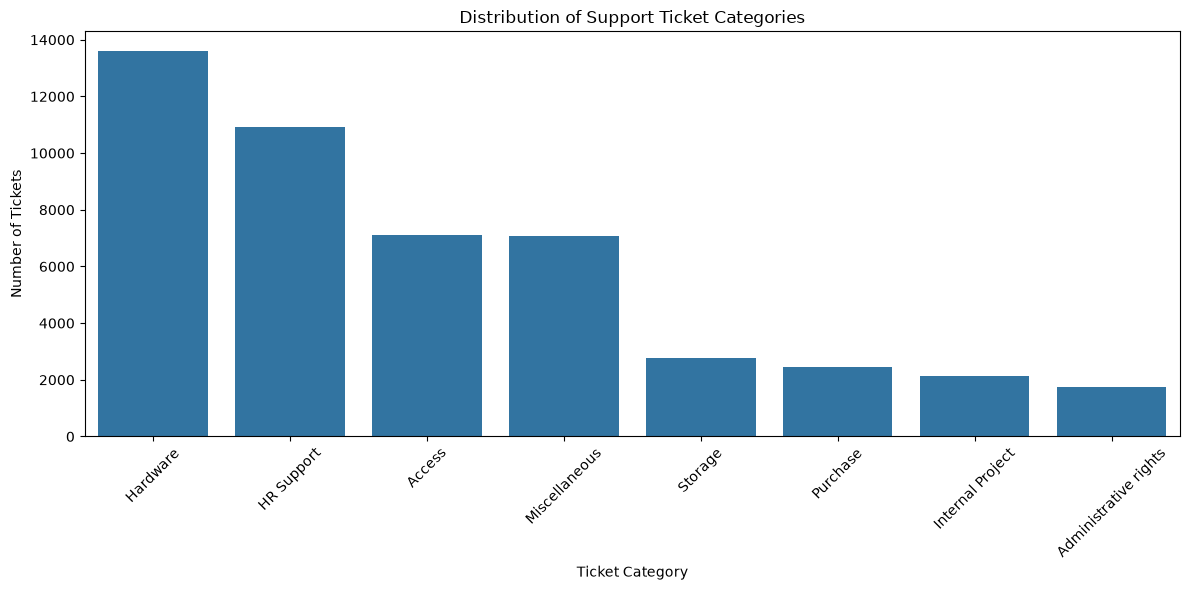

In [35]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Topic_group",
    order=df["Topic_group"].value_counts().index
)

plt.title("Distribution of Support Ticket Categories")
plt.xlabel("Ticket Category")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
category_counts = df["Topic_group"].value_counts()

print("Largest category:", category_counts.max())
print("Smallest category:", category_counts.min())
print("Imbalance ratio:", round(category_counts.max() / category_counts.min(), 2))

Largest category: 13617
Smallest category: 1760
Imbalance ratio: 7.74


In [40]:
df["character_count"] = df["Document"].str.len()
df["word_count"] = df["Document"].str.split().str.len()
df[["Document", "character_count", "word_count"]].head(10)

,Document,character_count,word_count
0,connection with icon icon dear please setup ic...,111,18
1,work experience user work experience user hi w...,124,19
2,requesting for meeting requesting meeting hi p...,93,14
3,reset passwords for external accounts re expir...,948,145
4,mail verification warning hi has got attached ...,115,15
5,mail please dear looks blacklisted receiving m...,110,15
6,prod servers tunneling prod tunneling va la tu...,906,141
7,access request dear modules report report cost...,65,10
8,reset passwords for our client and passwords c...,79,12
9,direct reports missing time please action repo...,619,91


In [41]:
df[["character_count", "word_count"]].describe()

,character_count,word_count
count,47837.000000,47837.000000
mean,291.881263,43.597341
std,388.171200,56.736800
min,7.000000,2.000000
25%,110.000000,17.000000
50%,175.000000,26.000000
75%,304.000000,46.000000
max,7015.000000,981.000000


In [42]:
df.loc[df["word_count"].idxmin(), ["Document", "word_count"]]

Document      open si
word_count          2
Name: 4215, dtype: object

In [43]:
df.loc[df["word_count"].idxmax(), ["Document", "word_count"]]

Document      complete tab re complete tab please hi ll have...
word_count                                                  981
Name: 39728, dtype: object

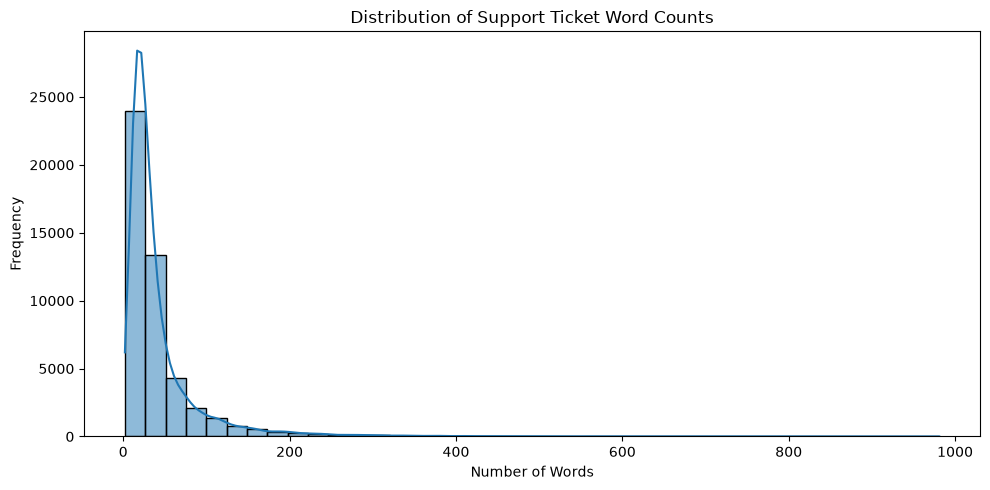

In [44]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="word_count", bins=40, kde=True)

plt.title("Distribution of Support Ticket Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

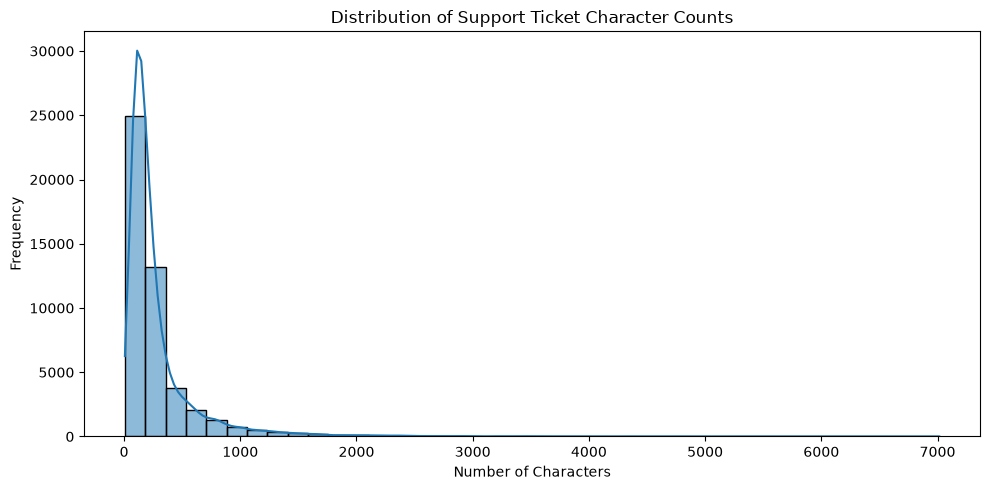

In [45]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="character_count", bins=40, kde=True)

plt.title("Distribution of Support Ticket Character Counts")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [ ]:
#most frequent words

all_text = " ".join(df["Document"].astype(str)).lower()

words = re.findall(r"\b[a-z]+\b", all_text)

word_frequency = Counter(words)

word_frequency.most_common(20)

[('please', 70212),
 ('pm', 28902),
 ('hi', 28498),
 ('regards', 27212),
 ('thank', 24962),
 ('for', 24456),
 ('hello', 23025),
 ('you', 21828),
 ('re', 21034),
 ('thanks', 19852),
 ('sent', 14717),
 ('kind', 13241),
 ('access', 13153),
 ('help', 11173),
 ('tuesday', 10896),
 ('with', 10555),
 ('wednesday', 10428),
 ('dear', 10320),
 ('thursday', 9935),
 ('can', 9526)]

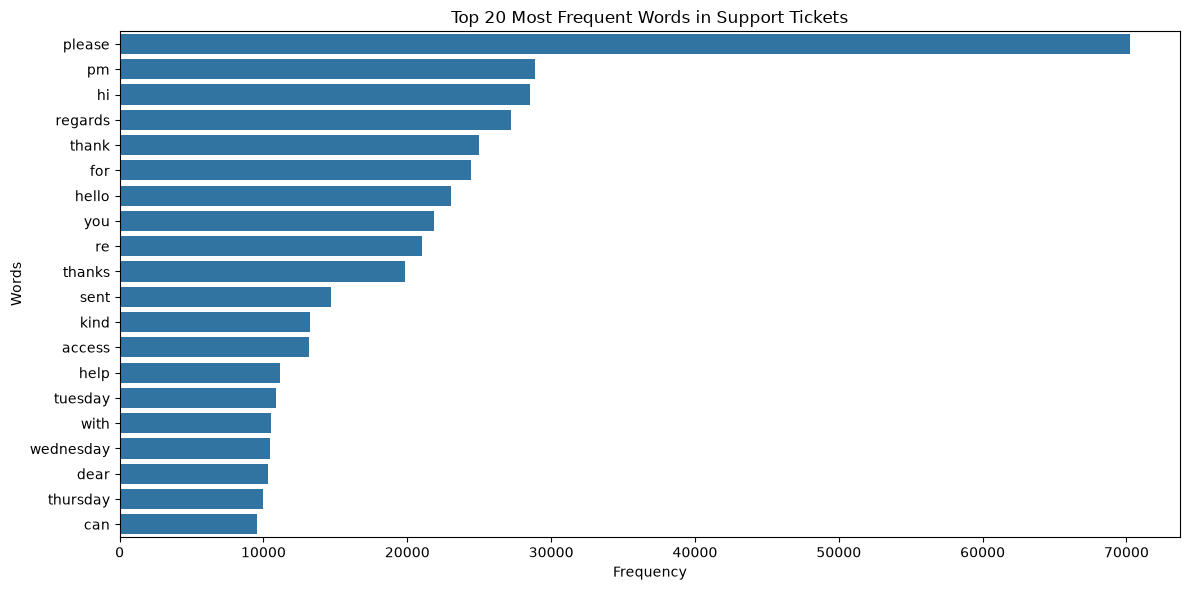

In [47]:
#20 most frequent words

top_words = word_frequency.most_common(20)

words_df = pd.DataFrame(top_words, columns=["Word", "Frequency"])

plt.figure(figsize=(12, 6))

sns.barplot(data=words_df, x="Frequency", y="Word")

plt.title("Top 20 Most Frequent Words in Support Tickets")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.tight_layout()
plt.show()

In [48]:
stop_words = set(stopwords.words("english"))

filtered_words = [word for word in words if word not in stop_words]

filtered_frequency = Counter(filtered_words)

filtered_frequency.most_common(20)

[('please', 70212),
 ('pm', 28902),
 ('hi', 28498),
 ('regards', 27212),
 ('thank', 24962),
 ('hello', 23025),
 ('thanks', 19852),
 ('sent', 14717),
 ('kind', 13241),
 ('access', 13153),
 ('help', 11173),
 ('tuesday', 10896),
 ('wednesday', 10428),
 ('dear', 10320),
 ('thursday', 9935),
 ('friday', 9441),
 ('best', 9390),
 ('error', 9291),
 ('issue', 8802),
 ('july', 8790)]

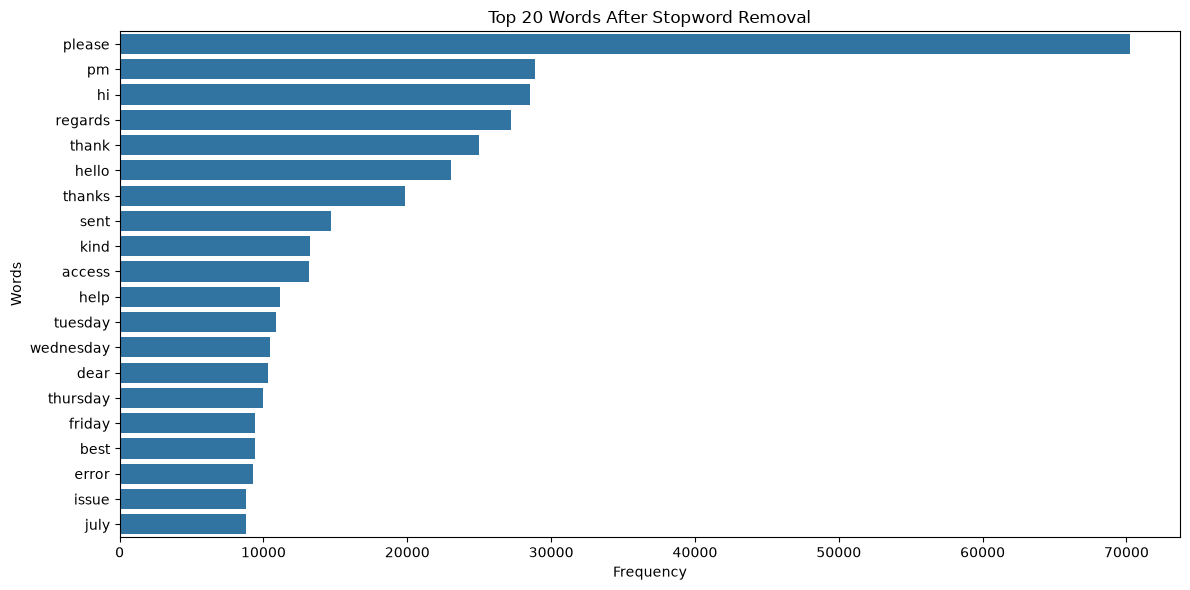

In [49]:
top_filtered_words = filtered_frequency.most_common(20)

filtered_df = pd.DataFrame(top_filtered_words, columns=["Word", "Frequency"])

plt.figure(figsize=(12, 6))

sns.barplot(data=filtered_df, x="Frequency", y="Word")

plt.title("Top 20 Words After Stopword Removal")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.tight_layout()
plt.show()

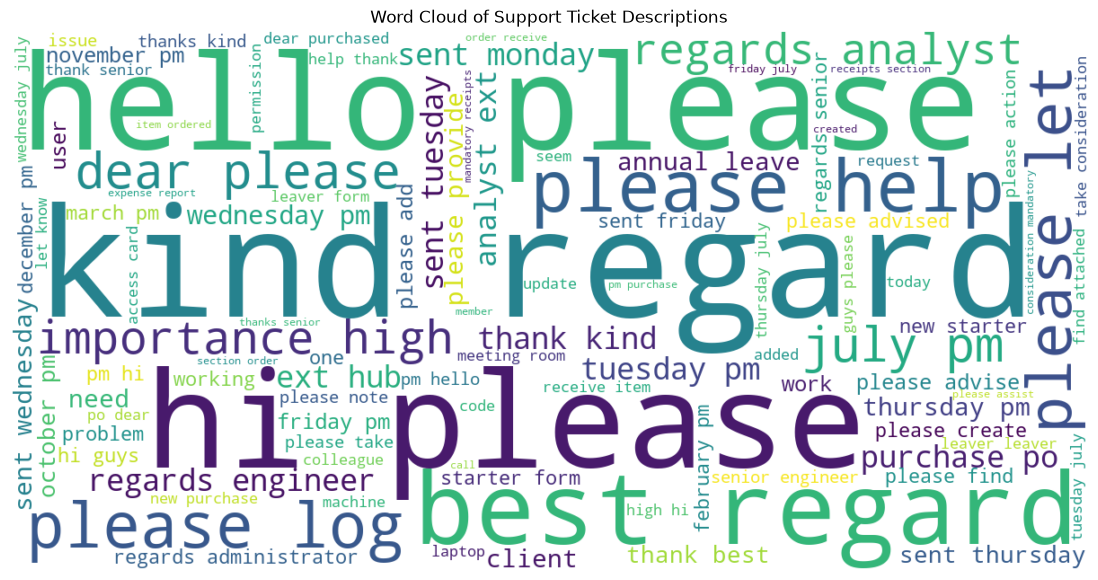

In [51]:
#word cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(" ".join(filtered_words))

plt.figure(figsize=(14, 7))

plt.imshow(wordcloud, interpolation="bilinear")

plt.axis("off")

plt.title("Word Cloud of Support Ticket Descriptions")

plt.show()

In [53]:
#most frequent words in each category

for topic in df["Topic_group"].unique():
    topic_text = " ".join(df.loc[df["Topic_group"] == topic, "Document"]).lower()
    topic_words = re.findall(r"\b[a-z]+\b", topic_text)
    topic_frequency = Counter(topic_words)

    print("\n", topic)
    print(topic_frequency.most_common(10))


 Hardware
[('please', 19401), ('you', 10095), ('hi', 9143), ('regards', 9038), ('for', 8909), ('re', 8778), ('pm', 7903), ('hello', 7666), ('thank', 7551), ('sent', 6741)]

 Access
[('please', 9006), ('confluence', 4587), ('pm', 4401), ('hi', 4001), ('regards', 3440), ('hello', 3182), ('thanks', 3150), ('thank', 3097), ('card', 2656), ('user', 2654)]

 Miscellaneous
[('please', 11258), ('hi', 4660), ('pm', 4605), ('change', 4390), ('for', 4354), ('regards', 4116), ('thank', 3866), ('hello', 3405), ('thanks', 3264), ('add', 3197)]

 HR Support
[('please', 16289), ('pm', 6477), ('thank', 6192), ('hi', 6092), ('for', 5950), ('leaver', 5646), ('regards', 5386), ('hello', 5383), ('error', 4778), ('form', 4570)]

 Purchase
[('please', 4744), ('purchase', 3792), ('po', 3764), ('administrator', 2112), ('log', 1943), ('regards', 1824), ('order', 1823), ('receive', 1660), ('kind', 1654), ('dear', 1640)]

 Administrative rights
[('upgrade', 2745), ('please', 2383), ('you', 1699), ('for', 1283), 

In [54]:
#average ticket lengths across categories

topic_lengths = df.groupby("Topic_group")[["word_count", "character_count"]].mean()

topic_lengths


,word_count,character_count
Topic_group,,
Access,35.600000,242.338667
Administrative rights,50.361932,339.182955
HR Support,37.766651,249.252313
Hardware,56.273041,375.408240
Internal Project,37.706937,250.317603
Miscellaneous,42.953966,286.876487
Purchase,34.932630,244.642857
Storage,34.409795,233.347137


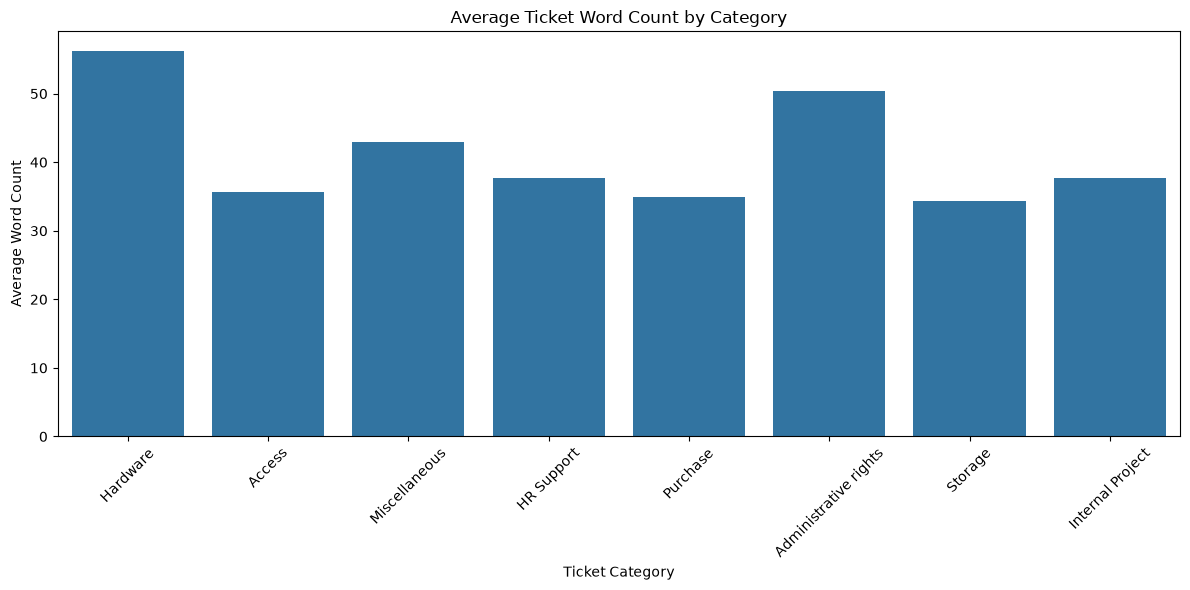

In [55]:
plt.figure(figsize=(12, 6))

sns.barplot(data=df, x="Topic_group", y="word_count", errorbar=None)

plt.title("Average Ticket Word Count by Category")
plt.xlabel("Ticket Category")
plt.ylabel("Average Word Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

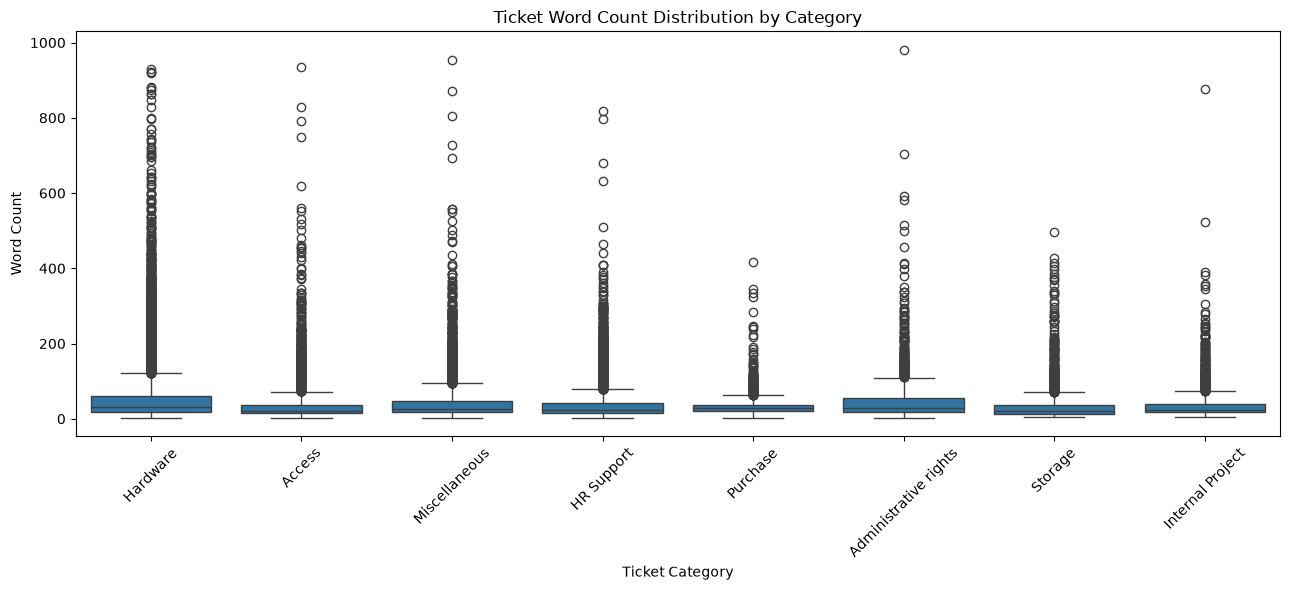

In [56]:
plt.figure(figsize=(13, 6))

sns.boxplot(data=df, x="Topic_group", y="word_count")

plt.title("Ticket Word Count Distribution by Category")
plt.xlabel("Ticket Category")
plt.ylabel("Word Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [61]:
df[["word_count", "character_count"]].corr()

,word_count,character_count
word_count,1.000000,0.995118
character_count,0.995118,1.000000


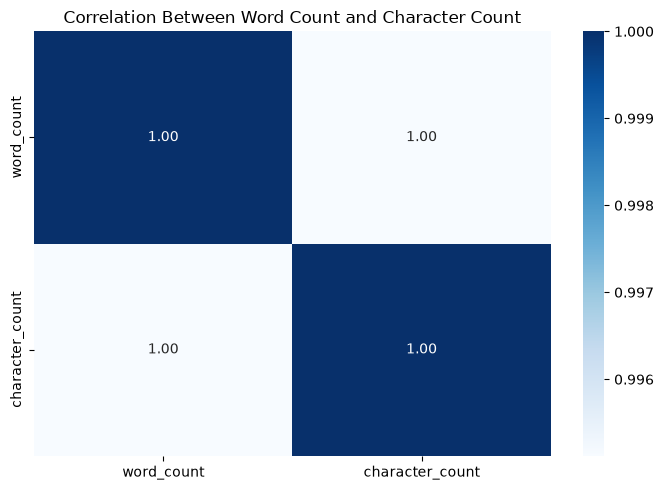

In [58]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    df[["word_count", "character_count"]].corr(),
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Correlation Between Word Count and Character Count")
plt.tight_layout()
plt.show()

Key EDA Findings
1. The dataset contains 47,837 support tickets across 8 categories.
2. Hardware is the largest category, representing approximately 28.47% of the dataset.
3. Administrative rights is the smallest category, representing approximately 3.68%.
4. The dataset has class imbalance, which should be considered during model training and evaluation.
5. Tickets contain an average of approximately 44 words, with substantial variation in length.
6. Common words include greetings and email expressions such as "please", "hi", "regards" and "thank".
7. Each category contains distinctive technical terms that may help the model distinguish between ticket types.
8. Word count and character count have a very strong positive correlation of 0.9951.

In [62]:
df["cleaned_text"] = df["Document"].copy()

df[["Document", "cleaned_text"]].head()

,Document,cleaned_text
0,connection with icon icon dear please setup ic...,connection with icon icon dear please setup ic...
1,work experience user work experience user hi w...,work experience user work experience user hi w...
2,requesting for meeting requesting meeting hi p...,requesting for meeting requesting meeting hi p...
3,reset passwords for external accounts re expir...,reset passwords for external accounts re expir...
4,mail verification warning hi has got attached ...,mail verification warning hi has got attached ...


In [63]:
df["cleaned_text"] = df["cleaned_text"].str.lower()

df[["Document", "cleaned_text"]].head()

,Document,cleaned_text
0,connection with icon icon dear please setup ic...,connection with icon icon dear please setup ic...
1,work experience user work experience user hi w...,work experience user work experience user hi w...
2,requesting for meeting requesting meeting hi p...,requesting for meeting requesting meeting hi p...
3,reset passwords for external accounts re expir...,reset passwords for external accounts re expir...
4,mail verification warning hi has got attached ...,mail verification warning hi has got attached ...


In [64]:
df["cleaned_text"] = df["cleaned_text"].apply(
    lambda text: re.sub(r"http\S+|www\S+", "", text)
)

df[["Document", "cleaned_text"]].head()

,Document,cleaned_text
0,connection with icon icon dear please setup ic...,connection with icon icon dear please setup ic...
1,work experience user work experience user hi w...,work experience user work experience user hi w...
2,requesting for meeting requesting meeting hi p...,requesting for meeting requesting meeting hi p...
3,reset passwords for external accounts re expir...,reset passwords for external accounts re expir...
4,mail verification warning hi has got attached ...,mail verification warning hi has got attached ...


In [65]:
df["cleaned_text"] = df["cleaned_text"].apply(
    lambda text: re.sub(r"\S+@\S+", "", text)
)

df[["Document", "cleaned_text"]].head()

,Document,cleaned_text
0,connection with icon icon dear please setup ic...,connection with icon icon dear please setup ic...
1,work experience user work experience user hi w...,work experience user work experience user hi w...
2,requesting for meeting requesting meeting hi p...,requesting for meeting requesting meeting hi p...
3,reset passwords for external accounts re expir...,reset passwords for external accounts re expir...
4,mail verification warning hi has got attached ...,mail verification warning hi has got attached ...


In [66]:
df["cleaned_text"] = df["cleaned_text"].apply(
    lambda text: text.translate(str.maketrans("", "", string.punctuation))
)

df[["Document", "cleaned_text"]].head()

,Document,cleaned_text
0,connection with icon icon dear please setup ic...,connection with icon icon dear please setup ic...
1,work experience user work experience user hi w...,work experience user work experience user hi w...
2,requesting for meeting requesting meeting hi p...,requesting for meeting requesting meeting hi p...
3,reset passwords for external accounts re expir...,reset passwords for external accounts re expir...
4,mail verification warning hi has got attached ...,mail verification warning hi has got attached ...


In [67]:
df["cleaned_text"] = df["cleaned_text"].apply(
    lambda text: re.sub(r"\s+", " ", text).strip()
)

df[["Document", "cleaned_text"]].head()

,Document,cleaned_text
0,connection with icon icon dear please setup ic...,connection with icon icon dear please setup ic...
1,work experience user work experience user hi w...,work experience user work experience user hi w...
2,requesting for meeting requesting meeting hi p...,requesting for meeting requesting meeting hi p...
3,reset passwords for external accounts re expir...,reset passwords for external accounts re expir...
4,mail verification warning hi has got attached ...,mail verification warning hi has got attached ...


In [68]:
stop_words = set(stopwords.words("english"))

df["cleaned_text"] = df["cleaned_text"].apply(
    lambda text: " ".join(
        word for word in text.split() if word not in stop_words
    )
)

df[["Document", "cleaned_text"]].head()

,Document,cleaned_text
0,connection with icon icon dear please setup ic...,connection icon icon dear please setup icon pe...
1,work experience user work experience user hi w...,work experience user work experience user hi w...
2,requesting for meeting requesting meeting hi p...,requesting meeting requesting meeting hi pleas...
3,reset passwords for external accounts re expir...,reset passwords external accounts expire days ...
4,mail verification warning hi has got attached ...,mail verification warning hi got attached plea...


In [69]:
email_words = {
    "please", "hi", "hello", "dear", "thanks",
    "thank", "regards", "kind", "best", "pm"
}

df["cleaned_text"] = df["cleaned_text"].apply(
    lambda text: " ".join(
        word for word in text.split() if word not in email_words
    )
)

df[["Document", "cleaned_text"]].head()

,Document,cleaned_text
0,connection with icon icon dear please setup ic...,connection icon icon setup icon per icon engin...
1,work experience user work experience user hi w...,work experience user work experience user work...
2,requesting for meeting requesting meeting hi p...,requesting meeting requesting meeting help fol...
3,reset passwords for external accounts re expir...,reset passwords external accounts expire days ...
4,mail verification warning hi has got attached ...,mail verification warning got attached address...


In [70]:
df["original_word_count"] = df["Document"].str.split().str.len()
df["cleaned_word_count"] = df["cleaned_text"].str.split().str.len()

df[["original_word_count", "cleaned_word_count"]].describe()

,original_word_count,cleaned_word_count
count,47837.000000,47837.0000
mean,43.597341,32.1891
std,56.736800,43.5643
min,2.000000,0.0000
25%,17.000000,12.0000
50%,26.000000,19.0000
75%,46.000000,34.0000
max,981.000000,808.0000


In [71]:
(df["cleaned_text"].str.strip() == "").sum()

np.int64(1)

In [72]:
df = df[df["cleaned_text"].str.strip() != ""].copy()

df.shape

(47836, 7)

In [73]:
#lemmatisation

lemmatizer = WordNetLemmatizer()

df["cleaned_text"] = df["cleaned_text"].apply(
    lambda text: " ".join(
        lemmatizer.lemmatize(word) for word in text.split()
    )
)

df[["Document", "cleaned_text"]].head()

,Document,cleaned_text
0,connection with icon icon dear please setup ic...,connection icon icon setup icon per icon engin...
1,work experience user work experience user hi w...,work experience user work experience user work...
2,requesting for meeting requesting meeting hi p...,requesting meeting requesting meeting help fol...
3,reset passwords for external accounts re expir...,reset password external account expire day ask...
4,mail verification warning hi has got attached ...,mail verification warning got attached address...


In [74]:
print("Dataset shape:", df.shape)
print("Empty tickets:", (df["cleaned_text"].str.strip() == "").sum())
print("Missing values:", df["cleaned_text"].isnull().sum())

df[["cleaned_text", "Topic_group"]].sample(5, random_state=42)

Dataset shape: (47836, 7)
Empty tickets: 0
Missing values: 0


,cleaned_text,Topic_group
44809,project assignment sent wednesday assignment c...,HR Support
20882,new purchase po wednesday february purchase po...,Purchase
41647,md code missing oracle sent tuesday code tried...,Internal Project
29138,new starter access thursday starter form find ...,HR Support
9536,new phone phone taken work mobile phone speak ...,Hardware


In [102]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["cleaned_text"],
    df["Topic_group"],
    test_size=0.2,
    random_state=42,
    stratify=df["Topic_group"]
)

print("Training data:", X_train_text.shape)
print("Testing data:", X_test_text.shape)

Training data: (38268,)
Testing data: (9568,)


In [103]:
#TF-IDF

tfidf = TfidfVectorizer(max_features=5000)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (38268, 5000)
Testing features: (9568, 5000)


In [104]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (38268, 5000)
Testing data: (9568, 5000)


In [105]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [107]:
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions, average="weighted"))
print("Recall:", recall_score(y_test, rf_predictions, average="weighted"))
print("F1 Score:", f1_score(y_test, rf_predictions, average="weighted"))

Accuracy: 0.8497073578595318
Precision: 0.854967197380292
Recall: 0.8497073578595318
F1 Score: 0.8495563785266156


In [77]:
#Logistic Regression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_predictions))

Logistic Regression Accuracy: 0.8459448160535117


In [78]:
#Multinomial Naive Bayes

nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

nb_predictions = nb_model.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_predictions))


Naive Bayes Accuracy: 0.7622282608695652


In [79]:
#Linear Support Vector Machine

svm_model = LinearSVC()

svm_model.fit(X_train, y_train)

svm_predictions = svm_model.predict(X_test)

print("Linear SVM Accuracy:", accuracy_score(y_test, svm_predictions))


Linear SVM Accuracy: 0.8478260869565217


In [81]:
#Random Forest

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_predictions))

Random Forest Accuracy: 0.8497073578595318


In [108]:
#Model Evaluation

models = {
    "Logistic Regression": lr_predictions,
    "Naive Bayes": nb_predictions,
    "Linear SVM": svm_predictions,
    "Random Forest": rf_predictions
}

for name, predictions in models.items():
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, average="weighted"))
    print("Recall:", recall_score(y_test, predictions, average="weighted"))
    print("F1 Score:", f1_score(y_test, predictions, average="weighted"))


 Logistic Regression
Accuracy: 0.8459448160535117
Precision: 0.8507898830327308
Recall: 0.8459448160535117
F1 Score: 0.8457538235016561

 Naive Bayes
Accuracy: 0.7622282608695652
Precision: 0.7865635519996684
Recall: 0.7622282608695652
F1 Score: 0.7567014086268922

 Linear SVM
Accuracy: 0.8478260869565217
Precision: 0.8494435551066838
Recall: 0.8478260869565217
F1 Score: 0.8477354679253717

 Random Forest
Accuracy: 0.8497073578595318
Precision: 0.854967197380292
Recall: 0.8497073578595318
F1 Score: 0.8495563785266156


In [109]:
print(classification_report(y_test, rf_predictions))

                       precision    recall  f1-score   support

               Access       0.90      0.88      0.89      1425
Administrative rights       0.92      0.62      0.74       352
           HR Support       0.88      0.87      0.87      2183
             Hardware       0.78      0.89      0.83      2724
     Internal Project       0.90      0.82      0.86       424
        Miscellaneous       0.82      0.78      0.80      1412
             Purchase       0.97      0.85      0.91       493
              Storage       0.93      0.81      0.86       555

             accuracy                           0.85      9568
            macro avg       0.89      0.82      0.85      9568
         weighted avg       0.85      0.85      0.85      9568



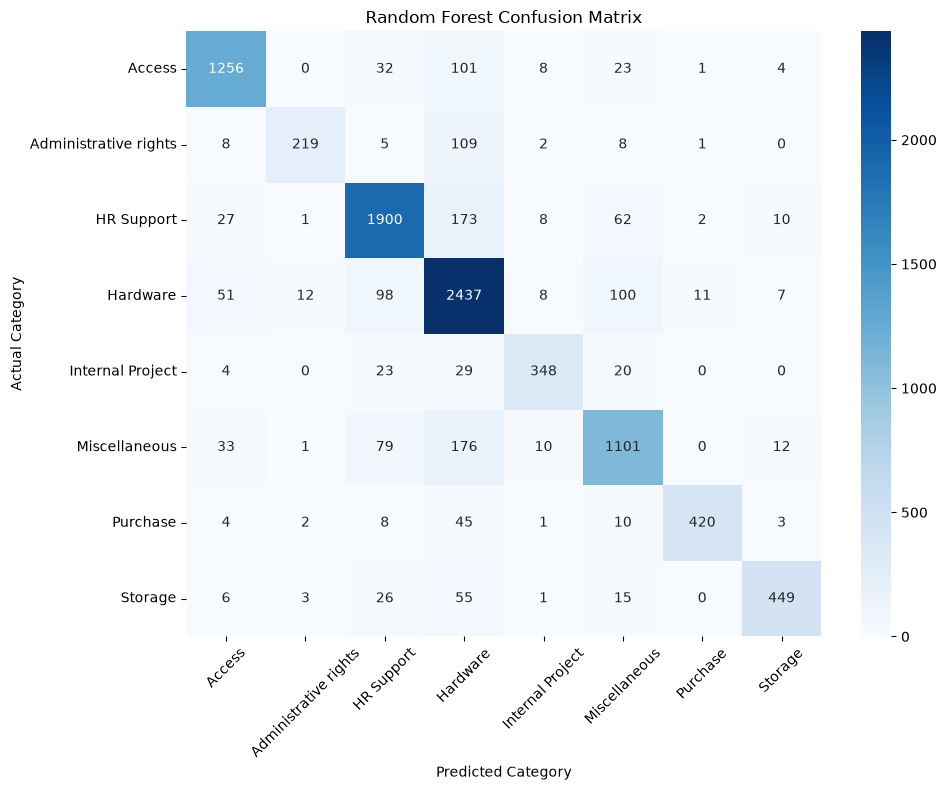

In [110]:
#Confusion Matrix

cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [111]:
#Feature Importance

feature_importance = pd.DataFrame({
    "Feature": tfidf.get_feature_names_out(),
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
927,connecting,0.019167
20,access,0.015582
695,character,0.014467
794,collapse,0.013666
649,carrying,0.012490
75,added,0.012335
4261,stat,0.012073
1836,folio,0.011488
4774,usual,0.011426
35,accordingly,0.011215


In [112]:
#Final Model Selection

joblib.dump(rf_model, "../models/random_forest_model.pkl")
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

['../models/tfidf_vectorizer.pkl']

In [114]:
joblib.dump(rf_model, "../models/random_forest_model.pkl")

['../models/random_forest_model.pkl']

In [115]:
#Testing

test_ticket = tfidf.transform([
    "I cannot access my company email account because my password is not working."
])

print("Predicted Category:", rf_model.predict(test_ticket)[0])

Predicted Category: HR Support


In [96]:
new_ticket_2 = ["I need a new laptop because my current computer is not working."]

In [ ]:
new_ticket_cleaned_2 = new_ticket_2[0].lower()
new_ticket_cleaned_2 = re.sub(r"http\S+|www\S+", "", new_ticket_cleaned_2)
new_ticket_cleaned_2 = re.sub(r"\S+@\S+", "", new_ticket_cleaned_2)
new_ticket_cleaned_2 = new_ticket_cleaned_2.translate(str.maketrans("", "", string.punctuation))
new_ticket_cleaned_2 = re.sub(r"\s+", " ", new_ticket_cleaned_2).strip()

new_ticket_cleaned_2 = " ".join(
    word for word in new_ticket_cleaned_2.split()
    if word not in stop_words and word not in email_words
)

new_ticket_cleaned_2 = " ".join(
    lemmatizer.lemmatize(word) for word in new_ticket_cleaned_2.split()
)

new_ticket_cleaned_2


'need new laptop current computer working'

In [98]:
new_ticket_vector_2 = tfidf.transform([new_ticket_cleaned_2])

prediction_2 = rf_model.predict(new_ticket_vector_2)

print("Predicted Category:", prediction_2[0])

Predicted Category: Hardware


In [99]:
new_ticket_3 = ["I need assistance updating my employee details and submitting a leave request."]

In [100]:
new_ticket_cleaned_3 = new_ticket_3[0].lower()
new_ticket_cleaned_3 = re.sub(r"http\S+|www\S+", "", new_ticket_cleaned_3)
new_ticket_cleaned_3 = re.sub(r"\S+@\S+", "", new_ticket_cleaned_3)
new_ticket_cleaned_3 = new_ticket_cleaned_3.translate(str.maketrans("", "", string.punctuation))
new_ticket_cleaned_3 = re.sub(r"\s+", " ", new_ticket_cleaned_3).strip()

new_ticket_cleaned_3 = " ".join(
    word for word in new_ticket_cleaned_3.split()
    if word not in stop_words and word not in email_words
)

new_ticket_cleaned_3 = " ".join(
    lemmatizer.lemmatize(word) for word in new_ticket_cleaned_3.split()
)

new_ticket_cleaned_3

'need assistance updating employee detail submitting leave request'

In [101]:
new_ticket_vector_3 = tfidf.transform([new_ticket_cleaned_3])

prediction_3 = rf_model.predict(new_ticket_vector_3)

print("Predicted Category:", prediction_3[0])

Predicted Category: HR Support


In [116]:
probabilities = rf_model.predict_proba(test_ticket)[0]

confidence = probabilities.max() * 100

print("Predicted Category:", rf_model.classes_[probabilities.argmax()])
print("Confidence:", round(confidence, 2), "%")

Predicted Category: HR Support
Confidence: 83.0 %


In [117]:
test_ticket_2 = tfidf.transform([
    "I need access to the company network and permission to use the shared system."
])

print("Predicted Category:", rf_model.predict(test_ticket_2)[0])

Predicted Category: HR Support


In [118]:
test_ticket_2 = tfidf.transform([
    "I need access to the company network and permission to use the shared system."
])

probabilities_2 = rf_model.predict_proba(test_ticket_2)[0]

pd.DataFrame({
    "Category": rf_model.classes_,
    "Probability": probabilities_2
}).sort_values(by="Probability", ascending=False)

,Category,Probability
2,HR Support,0.84
3,Hardware,0.06
7,Storage,0.05
5,Miscellaneous,0.04
0,Access,0.01
1,Administrative rights,0.00
4,Internal Project,0.00
6,Purchase,0.00


In [119]:
df[df["Topic_group"] == "HR Support"]["cleaned_text"].sample(10, random_state=42).tolist()

['access new pa friday february guy right involved level discipline lead',
 'new starter bucharest friday va date administration officer',
 'set new service sn friday sn find attached sn form',
 'access friday february assist infrastructure friday february senior administrator',
 'allocation allocation importance high make change allocate allocate blvd floor',
 'annual leave approver tuesday annual leave approver fine cover say next annual leave approver submitted leave request day noticed currently pending previously left therefore approve leave move approver account assigned get therefore since permanent replacement appointed yet ask approver interim approve leave request anyone working also backup approver work let okay leave beginning next approval assist next day much appreciated',
 'problem problem problem adding user started fine morning go screen start type name get following error help',
 'issue create expense item oracle service sent thursday issue create expense item create 

In [120]:
df[df["Topic_group"] == "Access"]["cleaned_text"].sample(10, random_state=42).tolist()

['confluence access wednesday february confluence confluence',
 'password reset open access help right laptop order reset password going expire day mention working remote location around december st also issue connecting open due right restriction think could fix somehow',
 'access tuesday create user created add head analysis',
 'password expire day friday october expire day per friday october expire day work around wait update commercial change street manchester mob october expire day confluence ask change automated reminder let good moment make friday october expire day importance high relates commercial change street manchester mob october expire day importance high expire day change pc press ctrl alt delete choose change ext originated detailed disclaimer automatically added gateway comply requirement arrived via cautious origin content reply contain sensitive information contractual obligation particularly vulnerable case adequate employed question speak consider environment prin

In [121]:
y_train.value_counts()

Topic_group
Hardware                 10893
HR Support                8732
Access                    5700
Miscellaneous             5648
Storage                   2222
Purchase                  1971
Internal Project          1695
Administrative rights     1407
Name: count, dtype: int64

In [122]:
access_indices = [
    i for i, category in enumerate(y_train)
    if category == "Access"
]

access_text = X_train[access_indices]

access_feature_scores = np.asarray(access_text.mean(axis=0)).ravel()

access_features = pd.DataFrame({
    "Feature": tfidf.get_feature_names_out(),
    "Score": access_feature_scores
}).sort_values(by="Score", ascending=False)

access_features.head(20)

,Feature,Score
927,connecting,0.100805
649,carrying,0.066506
4774,usual,0.065806
35,accordingly,0.048480
3119,pas,0.047431
2516,liable,0.047233
20,access,0.040911
1074,crucial,0.032596
3776,requisition,0.028226
3745,replicated,0.023818


In [124]:
test_ticket_3 = tfidf.transform([
    "Please grant me permission to access the company system and reset my login credentials."
])

print("Predicted Category:", rf_model.predict(test_ticket_3)[0])

Predicted Category: HR Support


In [125]:
ticket_vector = tfidf.transform([
    "Please grant me permission to access the company system and reset my login credentials."
])

print("Logistic Regression:", lr_model.predict(ticket_vector)[0])
print("Naive Bayes:", nb_model.predict(ticket_vector)[0])
print("Linear SVM:", svm_model.predict(ticket_vector)[0])
print("Random Forest:", rf_model.predict(ticket_vector)[0])

Logistic Regression: HR Support
Naive Bayes: HR Support
Linear SVM: HR Support
Random Forest: HR Support


In [126]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_predictions = nb_model.predict(X_test)

svm_model = LinearSVC()
svm_model.fit(X_train, y_train)
svm_predictions = svm_model.predict(X_test)

In [127]:
models = {
    "Logistic Regression": lr_model,
    "Naive Bayes": nb_model,
    "Linear SVM": svm_model,
    "Random Forest": rf_model
}

ticket_vector = tfidf.transform([
    "Please grant me permission to access the company system and reset my login credentials."
])

for name, model in models.items():
    print(name, ":", model.predict(ticket_vector)[0])

Logistic Regression : HR Support
Naive Bayes : HR Support
Linear SVM : HR Support
Random Forest : HR Support


In [128]:
models = {
    "Logistic Regression": lr_predictions,
    "Naive Bayes": nb_predictions,
    "Linear SVM": svm_predictions,
    "Random Forest": rf_predictions
}

for name, predictions in models.items():
    print("\n", name)
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("Precision:", round(precision_score(y_test, predictions, average="weighted"), 4))
    print("Recall:", round(recall_score(y_test, predictions, average="weighted"), 4))
    print("F1 Score:", round(f1_score(y_test, predictions, average="weighted"), 4))


 Logistic Regression
Accuracy: 0.8459
Precision: 0.8508
Recall: 0.8459
F1 Score: 0.8458

 Naive Bayes
Accuracy: 0.7622
Precision: 0.7866
Recall: 0.7622
F1 Score: 0.7567

 Linear SVM
Accuracy: 0.8478
Precision: 0.8494
Recall: 0.8478
F1 Score: 0.8477

 Random Forest
Accuracy: 0.8497
Precision: 0.855
Recall: 0.8497
F1 Score: 0.8496


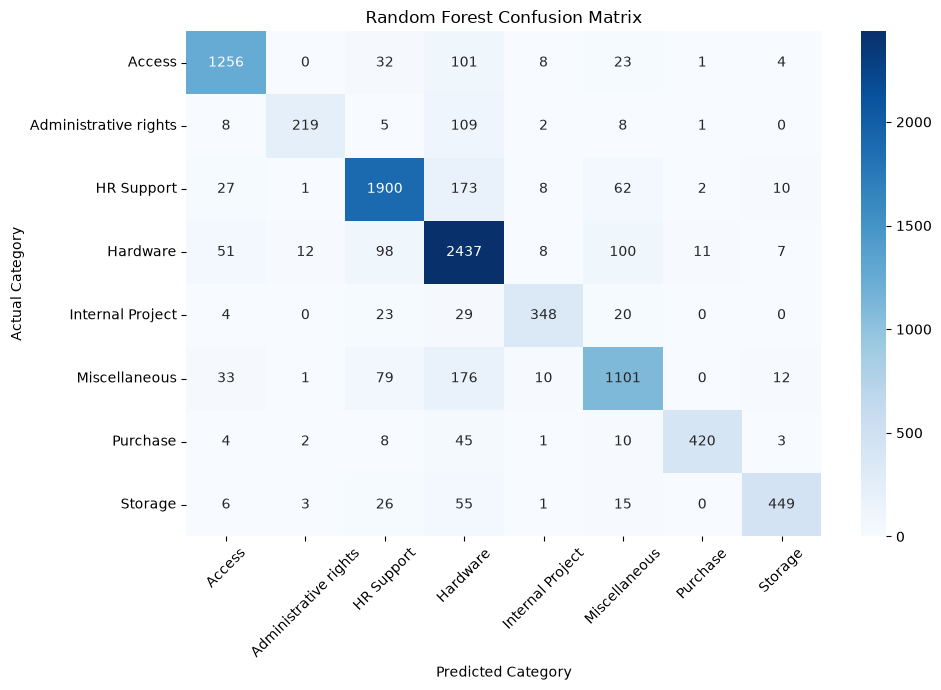

In [129]:
cm = confusion_matrix(y_test, rf_predictions, labels=rf_model.classes_)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Random Forest Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [131]:
print(classification_report(y_test, rf_predictions))

                       precision    recall  f1-score   support

               Access       0.90      0.88      0.89      1425
Administrative rights       0.92      0.62      0.74       352
           HR Support       0.88      0.87      0.87      2183
             Hardware       0.78      0.89      0.83      2724
     Internal Project       0.90      0.82      0.86       424
        Miscellaneous       0.82      0.78      0.80      1412
             Purchase       0.97      0.85      0.91       493
              Storage       0.93      0.81      0.86       555

             accuracy                           0.85      9568
            macro avg       0.89      0.82      0.85      9568
         weighted avg       0.85      0.85      0.85      9568



In [132]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": rf_predictions,
    "Ticket": X_test_text.values
})

misclassified = results[
    results["Actual"] != results["Predicted"]
]

print("Total misclassified:", len(misclassified))
print(misclassified.sample(10, random_state=42).to_string(index=False))

Total misclassified: 1438
               Actual             Predicted                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                Ticket
             Purchase            HR Support                                                                 

In [133]:
print(
    misclassified["Actual"]
    .value_counts()
)

print("\nMost common incorrect predictions:")
print(
    misclassified.groupby(["Actual", "Predicted"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Actual
Miscellaneous            311
Hardware                 287
HR Support               283
Access                   169
Administrative rights    133
Storage                  106
Internal Project          76
Purchase                  73
Name: count, dtype: int64

Most common incorrect predictions:
Actual                 Predicted    
Miscellaneous          Hardware         176
HR Support             Hardware         173
Administrative rights  Hardware         109
Access                 Hardware         101
Hardware               Miscellaneous    100
                       HR Support        98
Miscellaneous          HR Support        79
HR Support             Miscellaneous     62
Storage                Hardware          55
Hardware               Access            51
dtype: int64


In [134]:
category_comparison = pd.DataFrame({
    "Training Samples": y_train.value_counts(),
    "Testing Samples": y_test.value_counts(),
    "Misclassified": misclassified["Actual"].value_counts()
})

category_comparison["Error Rate"] = (
    category_comparison["Misclassified"] /
    category_comparison["Testing Samples"]
)

category_comparison["Error Rate"] = (
    category_comparison["Error Rate"] * 100
).round(2)

print(category_comparison.sort_values("Error Rate", ascending=False))

                       Training Samples  Testing Samples  Misclassified  \
Administrative rights              1407              352            133   
Miscellaneous                      5648             1412            311   
Storage                            2222              555            106   
Internal Project                   1695              424             76   
Purchase                           1971              493             73   
HR Support                         8732             2183            283   
Access                             5700             1425            169   
Hardware                          10893             2724            287   

                       Error Rate  
Administrative rights       37.78  
Miscellaneous               22.03  
Storage                     19.10  
Internal Project            17.92  
Purchase                    14.81  
HR Support                  12.96  
Access                      11.86  
Hardware                    10.54  


In [135]:
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_balanced.fit(X_train, y_train)

balanced_predictions = rf_balanced.predict(X_test)

print(classification_report(y_test, balanced_predictions))

                       precision    recall  f1-score   support

               Access       0.87      0.91      0.89      1425
Administrative rights       0.75      0.74      0.75       352
           HR Support       0.88      0.85      0.86      2183
             Hardware       0.84      0.80      0.82      2724
     Internal Project       0.77      0.95      0.85       424
        Miscellaneous       0.80      0.82      0.81      1412
             Purchase       0.92      0.90      0.91       493
              Storage       0.86      0.90      0.88       555

             accuracy                           0.85      9568
            macro avg       0.84      0.86      0.85      9568
         weighted avg       0.85      0.85      0.85      9568



In [136]:
for name, predictions in {
    "Original Random Forest": rf_predictions,
    "Balanced Random Forest": balanced_predictions
}.items():
    print("\n", name)
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("Weighted Precision:", round(precision_score(y_test, predictions, average="weighted"), 4))
    print("Weighted Recall:", round(recall_score(y_test, predictions, average="weighted"), 4))
    print("Weighted F1:", round(f1_score(y_test, predictions, average="weighted"), 4))
    print("Macro F1:", round(f1_score(y_test, predictions, average="macro"), 4))


 Original Random Forest
Accuracy: 0.8497
Weighted Precision: 0.855
Weighted Recall: 0.8497
Weighted F1: 0.8496
Macro F1: 0.8462

 Balanced Random Forest
Accuracy: 0.8456
Weighted Precision: 0.8466
Weighted Recall: 0.8456
Weighted F1: 0.8455
Macro F1: 0.8461


In [137]:
joblib.dump(rf_model, "../models/random_forest_model.pkl")
joblib.dump(rf_balanced, "../models/random_forest_balanced_model.pkl")
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

['../models/tfidf_vectorizer.pkl']

In [139]:
loaded_model = joblib.load("../models/random_forest_model.pkl")
loaded_tfidf = joblib.load("../models/tfidf_vectorizer.pkl")

sample_ticket = [
    "My laptop is not working and I need technical assistance."
]

sample_vector = loaded_tfidf.transform(sample_ticket)

prediction = loaded_model.predict(sample_vector)

print("Predicted Category:", prediction[0])

Predicted Category: Hardware


In [140]:
def preprocess_ticket(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"\S+@\S+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()

    words = text.split()
    words = [word for word in words if word not in stop_words]
    words = [word for word in words if word not in email_words]
    words = [lemmatizer.lemmatize(word) for word in words]

    return " ".join(words)


def predict_ticket(text):
    cleaned_text = preprocess_ticket(text)
    vector = loaded_tfidf.transform([cleaned_text])
    prediction = loaded_model.predict(vector)

    return prediction[0]

In [141]:
ticket = "I cannot log into my company account because my password is not working."

print("Predicted Category:", predict_ticket(ticket))

Predicted Category: Hardware


In [142]:
test_tickets = [
    "My laptop screen is broken and needs repair.",
    "Please grant me access to the company network.",
    "I need to submit my annual leave application."
]

for ticket in test_tickets:
    print("Ticket:", ticket)
    print("Prediction:", predict_ticket(ticket))
    print()

Ticket: My laptop screen is broken and needs repair.
Prediction: Hardware

Ticket: Please grant me access to the company network.
Prediction: HR Support

Ticket: I need to submit my annual leave application.
Prediction: HR Support



In [143]:
def predict_ticket(text):
    cleaned_text = preprocess_ticket(text)
    vector = loaded_tfidf.transform([cleaned_text])

    prediction = loaded_model.predict(vector)[0]
    probabilities = loaded_model.predict_proba(vector)[0]

    confidence = max(probabilities) * 100

    return prediction, round(confidence, 2)

In [144]:
ticket = "My laptop screen is broken and needs repair."

category, confidence = predict_ticket(ticket)

print("Predicted Category:", category)
print("Confidence:", confidence, "%")

Predicted Category: Hardware
Confidence: 98.0 %


In [145]:
test_tickets = [
    "My laptop screen is broken and needs repair.",
    "Please grant me access to the company network.",
    "I need to submit my annual leave application.",
    "I want to order a new office printer.",
    "My mailbox is full and I cannot receive emails."
]

for ticket in test_tickets:
    category, confidence = predict_ticket(ticket)

    print("Ticket:", ticket)
    print("Category:", category)
    print("Confidence:", confidence, "%")
    print()

Ticket: My laptop screen is broken and needs repair.
Category: Hardware
Confidence: 98.0 %

Ticket: Please grant me access to the company network.
Category: HR Support
Confidence: 87.0 %

Ticket: I need to submit my annual leave application.
Category: HR Support
Confidence: 87.0 %

Ticket: I want to order a new office printer.
Category: Storage
Confidence: 36.0 %

Ticket: My mailbox is full and I cannot receive emails.
Category: Hardware
Confidence: 56.0 %



In [146]:
def predict_ticket(text):
    cleaned_text = preprocess_ticket(text)
    vector = loaded_tfidf.transform([cleaned_text])

    probabilities = loaded_model.predict_proba(vector)[0]
    classes = loaded_model.classes_

    top_indices = np.argsort(probabilities)[::-1][:3]

    for index in top_indices:
        print(
            classes[index],
            ":",
            round(probabilities[index] * 100, 2),
            "%"
        )

In [147]:
predict_ticket("My mailbox is full and I cannot receive emails.")

Hardware : 56.0 %
HR Support : 36.0 %
Miscellaneous : 7.0 %


In [148]:
def predict_ticket(text):
    cleaned_text = preprocess_ticket(text)
    vector = loaded_tfidf.transform([cleaned_text])

    probabilities = loaded_model.predict_proba(vector)[0]
    classes = loaded_model.classes_

    top_indices = np.argsort(probabilities)[::-1][:3]

    prediction = classes[top_indices[0]]
    confidence = probabilities[top_indices[0]] * 100

    status = "Needs human review" if confidence < 70 else "Prediction accepted"

    print("Predicted Category:", prediction)
    print("Confidence:", round(confidence, 2), "%")
    print("Status:", status)
    print("\nTop 3 Categories:")

    for index in top_indices:
        print(classes[index], ":", round(probabilities[index] * 100, 2), "%")

In [149]:
predict_ticket("My mailbox is full and I cannot receive emails.")

Predicted Category: Hardware
Confidence: 56.0 %
Status: Needs human review

Top 3 Categories:
Hardware : 56.0 %
HR Support : 36.0 %
Miscellaneous : 7.0 %


In [150]:
print(df.columns.tolist())

['Document', 'Topic_group', 'character_count', 'word_count', 'cleaned_text', 'original_word_count', 'cleaned_word_count']


In [173]:
#priority function

def assign_priority(text):
    text = text.lower()

    high_keywords = [
        "critical", "urgent", "system down",
        "security breach", "unable to work",
        "business stopped", "data loss",
        "server failure", "complete outage"
    ]

    medium_keywords = [
    "error", "not working", "access issue",
    "malfunction", "problem", "damaged",
    "broken", "replacement", "password",
    "cannot access"
]

    if any(keyword in text for keyword in high_keywords):
        return "High"

    elif any(keyword in text for keyword in medium_keywords):
        return "Medium"

    else:
        return "Low"

In [175]:
priority_tickets = [
    "Critical system down and employees cannot work.",
    "I am experiencing an error when accessing my account.",
    "Please provide information about the software update."
]

for ticket in priority_tickets:
    print("Ticket:", ticket)
    print("Priority:", assign_priority(ticket))
    print()

Ticket: Critical system down and employees cannot work.
Priority: High

Ticket: I am experiencing an error when accessing my account.
Priority: Medium

Ticket: Please provide information about the software update.
Priority: Low



In [180]:
#Integrate category and priority predictions

def classify_support_ticket(text):
    cleaned_text = preprocess_ticket(text)
    vector = loaded_tfidf.transform([cleaned_text])

    probabilities = loaded_model.predict_proba(vector)[0]
    classes = loaded_model.classes_

    top_indices = np.argsort(probabilities)[::-1][:3]

    category = classes[top_indices[0]]
    confidence = probabilities[top_indices[0]] * 100
    priority = assign_priority(text)

    status = "Needs human review" if confidence < 70 or priority == "High" else "Prediction accepted"

    return {
        "Category": category,
        "Confidence": round(confidence, 2),
        "Priority": priority,
        "Status": status,
        "Alternative Categories": {
            classes[i]: float(round(probabilities[i] * 100, 2))
            for i in top_indices
        }
    }

In [177]:
ticket = "Critical system down. Employees cannot access their company accounts."

result = classify_support_ticket(ticket)

for key, value in result.items():
    print(key, ":", value)

Category : HR Support
Confidence : 83.0
Priority : High
Status : Needs human review
Alternative Categories : {'HR Support': np.float64(83.0), 'Hardware': np.float64(5.0), 'Storage': np.float64(4.0)}


In [178]:
test_tickets = [
    "Critical server failure. All employees are unable to work.",
    "My laptop keyboard is damaged and needs replacement.",
    "Please grant me access to the company database.",
    "I need assistance submitting my annual leave request.",
    "Please provide information about the latest software update."
]

for ticket in test_tickets:
    print("\nTicket:", ticket)

    result = classify_support_ticket(ticket)

    for key, value in result.items():
        print(key, ":", value)


Ticket: Critical server failure. All employees are unable to work.
Category : Hardware
Confidence : 59.0
Priority : High
Status : Needs human review
Alternative Categories : {'Hardware': np.float64(59.0), 'HR Support': np.float64(31.0), 'Miscellaneous': np.float64(5.0)}

Ticket: My laptop keyboard is damaged and needs replacement.
Category : Hardware
Confidence : 98.0
Priority : Medium
Status : Prediction accepted
Alternative Categories : {'Hardware': np.float64(98.0), 'HR Support': np.float64(1.0), 'Administrative rights': np.float64(1.0)}

Ticket: Please grant me access to the company database.
Category : HR Support
Confidence : 78.0
Priority : Low
Status : Prediction accepted
Alternative Categories : {'HR Support': np.float64(78.0), 'Access': np.float64(7.0), 'Storage': np.float64(5.0)}

Ticket: I need assistance submitting my annual leave request.
Category : HR Support
Confidence : 37.0
Priority : Low
Status : Needs human review
Alternative Categories : {'HR Support': np.float64(3

In [181]:
for ticket in test_tickets:
    result = classify_support_ticket(ticket)

    print("\nTicket:", ticket)
    print("Category:", result["Category"])
    print("Confidence:", result["Confidence"], "%")
    print("Priority:", result["Priority"])
    print("Status:", result["Status"])


Ticket: Critical server failure. All employees are unable to work.
Category: Hardware
Confidence: 59.0 %
Priority: High
Status: Needs human review

Ticket: My laptop keyboard is damaged and needs replacement.
Category: Hardware
Confidence: 98.0 %
Priority: Medium
Status: Prediction accepted

Ticket: Please grant me access to the company database.
Category: HR Support
Confidence: 78.0 %
Priority: Low
Status: Prediction accepted

Ticket: I need assistance submitting my annual leave request.
Category: HR Support
Confidence: 37.0 %
Priority: Low
Status: Needs human review

Ticket: Please provide information about the latest software update.
Category: Hardware
Confidence: 54.0 %
Priority: Low
Status: Needs human review
